# Customer Churn — Learn, Train & Test
**Milestone 1: historical classification.** Open in Google Colab and use **Runtime → Run all**, or run one cell at a time to learn.

This notebook uses IBM's **fictional** telecom sample. `Churn` records a historical outcome. It has no verified customer observation dates or future outcome windows. Test results are retrospective classification results, **not evidence of next-30-day prediction**. Predictor availability before churn cannot be fully established from this snapshot.

You will complete cleaning, encoding, feature engineering, feature selection, model training, a small validation-based parameter search, threshold selection and held-out testing. Steps are explicit; no scikit-learn Pipeline object is used.

**Milestone 2 remains:** choose longitudinal data, establish observation dates and label windows, train on earlier periods and test later periods. A real-time prediction app and deployment are also later work.

Source: [IBM dataset](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv). [IBM sample description](https://www.ibm.com/docs/en/cognos-analytics/12.1.x?topic=samples-telco-customer-churn).

## 1. Import tools and load the data
The CSV loads automatically. No large-file upload is needed. A local `Telco.csv`, if present, is used instead. Keep the initial raw copy unchanged.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, brier_score_loss,
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
raw = pd.read_csv('Telco.csv' if Path('Telco.csv').exists() else URL)
print('Rows, columns:', raw.shape)
print('scikit-learn:', sklearn.__version__)
print(raw.head(3).to_string(index=False))

Rows, columns: (7043, 21)
scikit-learn: 1.8.0
customerID gender  SeniorCitizen Partner Dependents  tenure PhoneService    MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies       Contract PaperlessBilling    PaymentMethod  MonthlyCharges TotalCharges Churn
7590-VHVEG Female              0     Yes         No       1           No No phone service             DSL             No          Yes               No          No          No              No Month-to-month              Yes Electronic check           29.85        29.85    No
5575-GNVDE   Male              0      No         No      34          Yes               No             DSL            Yes           No              Yes          No          No              No       One year               No     Mailed check           56.95       1889.5    No
3668-QPYBK   Male              0      No         No       2          Yes               No             DSL            Yes         

## 2. Clean and audit
Whitespace-only total charges are missing values, not zero charges. Convert that column to numeric. Verify one row per customer and a valid target. Rules here do not learn statistics from the data. We do not remove records merely because they have the same features.

In [2]:
data = raw.copy()
for column in data.select_dtypes(include='object'):
    data[column] = data[column].str.strip()
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
assert data['customerID'].notna().all() and data['customerID'].is_unique
assert data['Churn'].isin(['Yes', 'No']).all()
print('Duplicate rows:', data.duplicated().sum())
print('Missing cells:\n', data.isna().sum()[data.isna().any()].to_string())
y = data['Churn'].map({'No': 0, 'Yes': 1}).astype(int)
X = data.drop(columns=['Churn', 'customerID'])
# Keep the ID outside model inputs, for later identification only.
customer_ids = data['customerID'].copy()

Duplicate rows: 0
Missing cells:
 TotalCharges    11


## 3. Split before learning transformations
60% training, 20% validation, 20% test, stratified to retain a similar churn balance. Training teaches the models. Validation selects models, feature subsets and thresholds. Test is reserved for one final assessment. This is a **random split**, not a time split.

In [3]:
X_develop, X_test, y_develop, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_develop, y_develop, test_size=0.25, stratify=y_develop, random_state=SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print('Train / validation / test:', len(X_train), len(X_val), len(X_test))
print('Training churn share:', f'{y_train.mean():.1%}')

Train / validation / test: 4225 1409 1409
Training churn share: 26.5%


## 4. Explore training data
Explore only the training partition while making modelling choices. A large non-churn group means accuracy alone can be misleading.

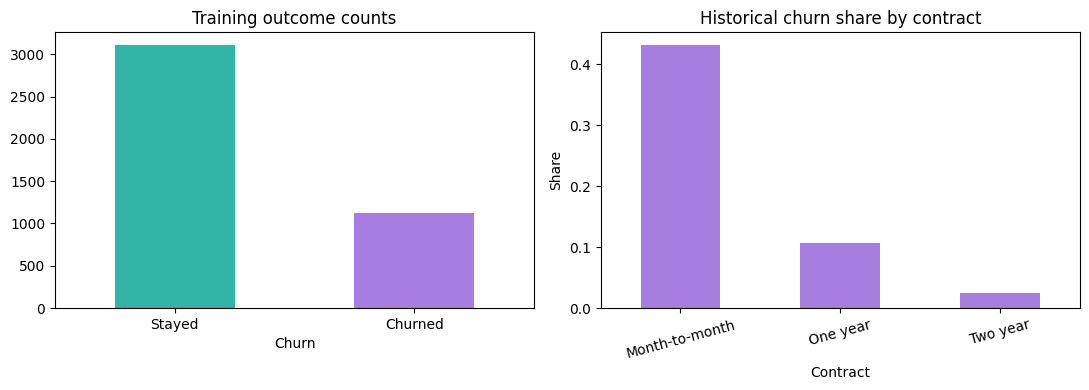

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y_train.value_counts().sort_index().plot.bar(ax=axes[0], color=['#32b5a6','#a77de0'])
axes[0].set_xticklabels(['Stayed','Churned'], rotation=0)
axes[0].set_title('Training outcome counts')
X_train.assign(Churn=y_train).groupby('Contract')['Churn'].mean().plot.bar(
    ax=axes[1], color='#a77de0')
axes[1].set_title('Historical churn share by contract')
axes[1].set_ylabel('Share'); axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

## 5. Engineer features
`ServiceCount` counts selected subscribed services. `AutomaticPayment` marks bank/credit-card automatic payment. These are deterministic transformations, so they can be applied independently to each split. They are associations, not proven causes of churn.

In [5]:
def engineer(frame):
    result = frame.copy()
    services = ['PhoneService','OnlineSecurity','OnlineBackup','DeviceProtection',
                'TechSupport','StreamingTV','StreamingMovies']
    result['ServiceCount'] = result[services].eq('Yes').sum(axis=1)
    result['AutomaticPayment'] = result['PaymentMethod'].isin([
        'Bank transfer (automatic)', 'Credit card (automatic)']).astype(int)
    return result
train = engineer(X_train)
validation = engineer(X_val)
test = engineer(X_test)
print(train[['ServiceCount','AutomaticPayment']].head().to_string())

      ServiceCount  AutomaticPayment
2312             1                 0
5227             3                 0
6404             6                 0
88               1                 0
6496             4                 0


## 6. Impute, encode and scale
Fit every transformer on **training data only**. Numeric missing values use the training median. Category missing values use the training mode. One-hot encoding converts each category to a 0/1 column without inventing an order. An unseen category maps to zeros in its feature group. Scaling learns the training mean and standard deviation. We retain all dummy columns; regularised models handle the redundancy.

**Interview explanation:** “I used the same fitted encoder for training, validation and test data, so their columns stay consistent.”

In [6]:
numeric_columns = train.select_dtypes(include='number').columns.tolist()
categorical_columns = train.select_dtypes(exclude='number').columns.tolist()
number_imputer = SimpleImputer(strategy='median')
category_imputer = SimpleImputer(strategy='most_frequent')
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
scaler = StandardScaler()

train_numbers = number_imputer.fit_transform(train[numeric_columns])
train_categories = category_imputer.fit_transform(train[categorical_columns])
encoded_train_categories = encoder.fit_transform(train_categories)
scaled_train_numbers = scaler.fit_transform(train_numbers)
A_train = np.hstack([scaled_train_numbers, encoded_train_categories])

def transform(frame):
    numbers = scaler.transform(number_imputer.transform(frame[numeric_columns]))
    categories = encoder.transform(category_imputer.transform(frame[categorical_columns]))
    return np.hstack([numbers, categories])

A_val = transform(validation)
A_test = transform(test)
feature_names = np.concatenate([numeric_columns,
    encoder.get_feature_names_out(categorical_columns)])
assert A_train.shape[1] == A_val.shape[1] == A_test.shape[1]
assert np.isfinite(A_train).all() and np.isfinite(A_test).all()
print('Encoded features:', len(feature_names))
print(feature_names[:15])

Encoded features: 47
['SeniorCitizen' 'tenure' 'MonthlyCharges' 'TotalCharges' 'ServiceCount'
 'AutomaticPayment' 'gender_Female' 'gender_Male' 'Partner_No'
 'Partner_Yes' 'Dependents_No' 'Dependents_Yes' 'PhoneService_No'
 'PhoneService_Yes' 'MultipleLines_No']


## 7. Feature selection
A training-only random forest ranks encoded features. We retain features whose importance is at least the median. This is a simple model-based method; its importance scores can favour continuous or correlated features. We compare **all features vs selected features** on validation data instead of assuming selection helps. A selected feature can be one dummy column, not a whole original variable.

In [7]:
ranking_model = RandomForestClassifier(n_estimators=150, min_samples_leaf=5,
    random_state=SEED, n_jobs=-1)
ranking_model.fit(A_train, y_train)
selector = SelectFromModel(ranking_model, prefit=True, threshold='median')
selected_names = feature_names[selector.get_support()]
print('Selected:', len(selected_names), 'of', len(feature_names))
print(selected_names)
feature_sets = {
    'All features': (A_train, A_val, A_test),
    'Selected features': (selector.transform(A_train), selector.transform(A_val),
                          selector.transform(A_test))
}

Selected: 24 of 47
['tenure' 'MonthlyCharges' 'TotalCharges' 'ServiceCount'
 'AutomaticPayment' 'gender_Female' 'gender_Male' 'Partner_Yes'
 'MultipleLines_No' 'MultipleLines_Yes' 'InternetService_DSL'
 'InternetService_Fiber optic' 'OnlineSecurity_No' 'OnlineSecurity_Yes'
 'OnlineBackup_No' 'DeviceProtection_No' 'TechSupport_No'
 'TechSupport_Yes' 'Contract_Month-to-month' 'Contract_One year'
 'Contract_Two year' 'PaperlessBilling_No' 'PaperlessBilling_Yes'
 'PaymentMethod_Electronic check']


## 8. Train and tune using validation data
We compare a dummy baseline, logistic regression, random forest and gradient boosting. The small parameter search changes logistic regularisation and forest depth. Choose by **validation average precision (AP)**, a precision–recall summary useful for imbalanced targets. AP is not exactly trapezoidal PR-AUC.

This first version uses a single validation split for transparency. It is **not cross-validation**. A later robustness check must refit preprocessing and selection inside each training fold.

In [8]:
results, fitted = [], {}
for feature_set, (a_train, a_val, _) in feature_sets.items():
    candidates = {'Dummy': DummyClassifier(strategy='prior')}
    for regularisation in [0.1, 1.0, 10.0]:
        candidates[f'Logistic C={regularisation}'] = LogisticRegression(
            C=regularisation, max_iter=2000, random_state=SEED)
    for depth in [6, None]:
        candidates[f'Random forest depth={depth}'] = RandomForestClassifier(
            n_estimators=150, max_depth=depth, min_samples_leaf=5,
            random_state=SEED, n_jobs=-1)
    candidates['Gradient boosting'] = GradientBoostingClassifier(
        n_estimators=100, max_depth=2, random_state=SEED)
    for name, estimator in candidates.items():
        estimator.fit(a_train, y_train)
        probabilities = estimator.predict_proba(a_val)[:, 1]
        key = (feature_set, name)
        fitted[key] = estimator
        results.append({'Features': feature_set, 'Model': name,
            'Validation AP': average_precision_score(y_val, probabilities),
            'Validation ROC-AUC': roc_auc_score(y_val, probabilities)})
leaderboard = pd.DataFrame(results).sort_values('Validation AP', ascending=False)
print(leaderboard.to_string(index=False))
winner = leaderboard.iloc[0]
chosen_features, chosen_name = winner['Features'], winner['Model']
best_model = fitted[(chosen_features, chosen_name)]
print('Chosen:', chosen_name, '/', chosen_features)

         Features                    Model  Validation AP  Validation ROC-AUC
     All features        Gradient boosting       0.646883            0.838996
Selected features        Gradient boosting       0.645244            0.838777
Selected features          Logistic C=10.0       0.643429            0.835795
     All features          Logistic C=10.0       0.642942            0.836641
Selected features           Logistic C=1.0       0.642641            0.835552
     All features           Logistic C=1.0       0.642258            0.835941
     All features           Logistic C=0.1       0.641971            0.835572
Selected features           Logistic C=0.1       0.640763            0.835320
     All features    Random forest depth=6       0.639283            0.837216
Selected features    Random forest depth=6       0.639127            0.836792
     All features Random forest depth=None       0.634627            0.836158
Selected features Random forest depth=None       0.632063       

## 9. Choose a threshold before the final test
A score threshold converts probabilities to Yes/No decisions. Choose the threshold with the best validation F1 among a small grid. F1 treats precision and recall equally; a real business may need a different cost rule. Keep this model fitted on training only, so its validation-chosen threshold remains associated with the same model.

In [9]:
_, selected_val, selected_test = feature_sets[chosen_features]
val_probability = best_model.predict_proba(selected_val)[:, 1]
thresholds = np.arange(0.15, 0.76, 0.05)
threshold_scores = [f1_score(y_val, val_probability >= t, zero_division=0)
                    for t in thresholds]
threshold = float(thresholds[np.argmax(threshold_scores)])
print('Chosen threshold:', round(threshold, 2))
print('Validation F1:', round(max(threshold_scores), 3))

Chosen threshold: 0.35
Validation F1: 0.632


## 10. Final test — do not tune after this
Report the held-out results even if disappointing. Accuracy counts all correct decisions. Precision describes how many flagged customers churned. Recall describes how many churners were found. F1 balances precision and recall. ROC-AUC and AP evaluate ranking. Brier score evaluates probability error (lower is better); it does not by itself establish calibration.

Precision@100 and recall@100 describe an illustrative capacity-limited historical ranking, **not retention impact**. Ties are broken reproducibly by row order.

Accuracy             0.7793
Precision            0.5655
Recall               0.7273
F1                   0.6363
Average precision    0.6653
ROC-AUC              0.8447
Brier score          0.1359
Precision@100        0.8200
Recall@100           0.2193


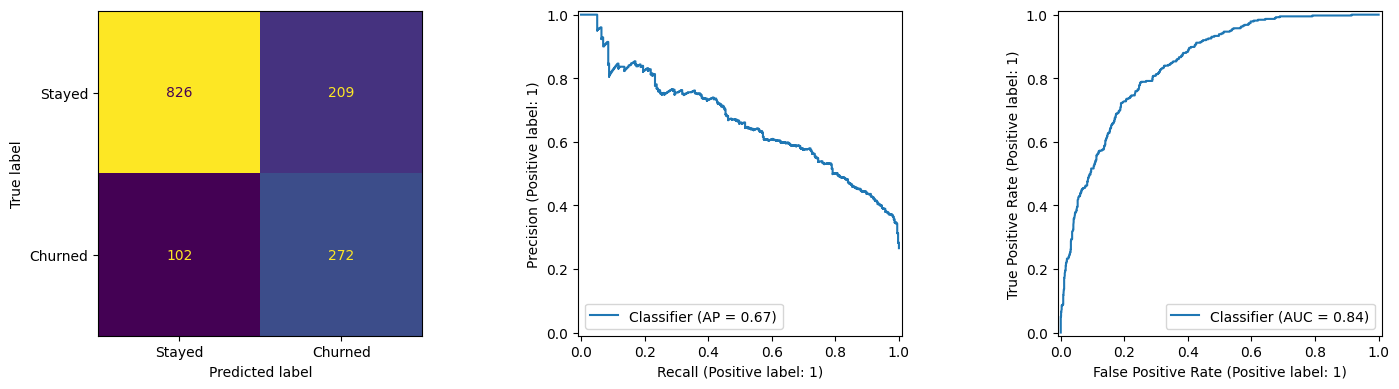

In [10]:
test_probability = best_model.predict_proba(selected_test)[:, 1]
test_prediction = (test_probability >= threshold).astype(int)
k = min(100, len(y_test))
top = np.argsort(-test_probability, kind='stable')[:k]
metrics = {
    'Accuracy': accuracy_score(y_test, test_prediction),
    'Precision': precision_score(y_test, test_prediction, zero_division=0),
    'Recall': recall_score(y_test, test_prediction, zero_division=0),
    'F1': f1_score(y_test, test_prediction, zero_division=0),
    'Average precision': average_precision_score(y_test, test_probability),
    'ROC-AUC': roc_auc_score(y_test, test_probability),
    'Brier score': brier_score_loss(y_test, test_probability),
    'Precision@100': float(y_test.iloc[top].mean()),
    'Recall@100': float(y_test.iloc[top].sum() / y_test.sum())
}
print(pd.Series(metrics).round(4).to_string())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction,
    display_labels=['Stayed','Churned'], ax=axes[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[1])
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[2])
plt.tight_layout(); plt.show()

## 11. Explain model reliance
Permutation importance asks how much validation AP falls when one encoded feature is shuffled. Correlated features can substitute for each other, so this is not causal importance. It is an explanation step, not another selection round.

In [11]:
importance = permutation_importance(best_model, selected_val, y_val,
    scoring='average_precision', n_repeats=3, random_state=SEED, n_jobs=1)
used_names = feature_names if chosen_features == 'All features' else selected_names
explanation = pd.Series(importance.importances_mean, index=used_names).sort_values(ascending=False)
print(explanation.head(12).round(4).to_string())

tenure                            0.0830
TotalCharges                      0.0819
Contract_Month-to-month           0.0547
InternetService_Fiber optic       0.0426
MonthlyCharges                    0.0267
OnlineSecurity_No                 0.0238
TechSupport_No                    0.0102
PaymentMethod_Electronic check    0.0099
MultipleLines_No                  0.0096
PaperlessBilling_No               0.0056
OnlineBackup_No                   0.0049
Contract_Two year                 0.0049


## 12. Save outputs and practise scoring an unseen row
The bundle saves the individual fitted steps; it is not a deployed app. The example is a held-out historical row treated as if its label were unknown. The score has no verified future horizon. Only load model files you trust; joblib deserialises executable Python objects.

In [12]:
import joblib
from zipfile import ZipFile
output = Path('churn_outputs'); output.mkdir(exist_ok=True)
leaderboard.to_csv(output/'validation_comparison.csv', index=False)
pd.Series(metrics, name='value').to_csv(output/'test_metrics.csv')
explanation.rename('validation_AP_drop').to_csv(output/'feature_importance.csv')
bundle = {'model': best_model, 'number_imputer': number_imputer,
    'category_imputer': category_imputer, 'encoder': encoder, 'scaler': scaler,
    'selector': selector, 'selected_features_used': chosen_features == 'Selected features',
    'numeric_columns': numeric_columns, 'categorical_columns': categorical_columns,
    'threshold': threshold, 'sklearn_version': sklearn.__version__,
    'scope': 'Historical IBM fictional sample classification; future horizon unverified'}
joblib.dump(bundle, output/'historical_churn_components.joblib')
example = X_test.iloc[[0]].copy()
example_ready = transform(engineer(example))
if chosen_features == 'Selected features':
    example_ready = selector.transform(example_ready)
score = best_model.predict_proba(example_ready)[0, 1]
assert np.isclose(score, test_probability[0])
print(f'Example historical classification score: {score:.1%}')
print('This is NOT a verified probability of churn in the next 30 days.')
with ZipFile('churn_results.zip', 'w') as archive:
    for file in output.iterdir(): archive.write(file, arcname=file.name)
print('Saved churn_results.zip — download it from the Colab Files panel.')

Example historical classification score: 3.5%
This is NOT a verified probability of churn in the next 30 days.
Saved churn_results.zip — download it from the Colab Files panel.


## What you should be able to explain
1. Why was customerID excluded?
2. Why did the encoder learn categories only from training data?
3. What is feature engineering versus feature selection?
4. Did selection help? Point to the validation comparison.
5. Why can accuracy be misleading here?
6. What do false positives and false negatives mean for outreach?
7. Why was the threshold chosen before testing?
8. Why is this not yet evidence of future-period prediction?

**Next milestones:** learn these steps, add fold-safe cross-validation, assess probability calibration, build the app, and implement dated future-window prediction on a suitable longitudinal dataset. Do not claim those milestones are complete yet.